# Dự báo nhiệt độ Hà Nội bằng Decision Tree

**Bài toán.** Tại giờ $t$, dùng dữ liệu thời tiết đã quan sát để dự báo nhiệt độ `temperature_2m` tại $t+1$ giờ, theo °C. Đây là hồi quy bằng một cây quyết định. Mỗi nút chọn một biến và một ngưỡng để giảm sai số bình phương, còn mỗi lá trả về trung bình của nhãn huấn luyện đi vào lá đó.

Hai phương án dùng cùng một loại cây. Persistence là mốc so sánh.

| Phương án | Nhãn cây học | Dự báo nhiệt độ tại $t+1$ |
|---|---|---|
| Trực tiếp | $T_{t+1}$ | Giá trị cây trả về |
| Theo biến thiên | $T_{t+1}-T_t$ | $T_t$ cộng với biến thiên do cây dự báo |
| Persistence | — | $T_t$ |

**Chạy lại.** Mở notebook bằng kernel Python có các thư viện trong `requirements.txt` rồi chọn **Run All**. Notebook dùng dữ liệu processed và mã dùng chung trong repo. Bảng, biểu đồ và kết quả đều nằm trong notebook. Cây đã fit được giữ trong biến `best_model` sau khi chạy.

## 1. Cấu hình và hợp đồng dữ liệu

Đọc danh sách biến ML đã chốt trong `data_processing/feature_selection.json`. Mỗi dòng đầu vào đại diện cho giờ $t$, có sẵn biến chu kỳ thời gian, nhiệt độ trễ 1/3/24 giờ, chênh lệch 1 giờ và trung bình 3 giờ. Đầu vào của cây là một dòng đã tạo biến tại giờ $t$, giữ nguyên thang đo.

Hai CSV processed được kiểm tra SHA-256 theo báo cáo. Chấp nhận cả bản xuống dòng LF và bản CRLF do Git checkout trên Windows.

In [1]:
from hashlib import sha256
from io import BytesIO
import json
from pathlib import Path
import sys

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import Markdown, display
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import ParameterGrid
from sklearn.tree import DecisionTreeRegressor, plot_tree

ROOT = Path.cwd().resolve()
if ROOT.name == "model":
    ROOT = ROOT.parent
if not (ROOT / "src/weather_data.py").is_file():
    raise FileNotFoundError("Chạy notebook từ thư mục gốc dự án hoặc thư mục model.")
sys.path.insert(0, str(ROOT))

from src.weather_data import build_forecast_dataset, load_feature_selection

TRAIN_PATH = ROOT / "data/processed/Hanoi_final.csv"
TEST_PATH = ROOT / "data/processed/Hanoi_test_final.csv"
REPORT_PATH = ROOT / "data_processing/feature_selection.json"

TARGET = "temperature_2m"
HORIZON = 1
VALIDATION_START = pd.Timestamp("2025-01-01")
TEST_START = pd.Timestamp("2026-01-01")
SEED = 42

report = json.loads(REPORT_PATH.read_text(encoding="utf-8"))
features = load_feature_selection(REPORT_PATH, TARGET, HORIZON)
if not pd.Timestamp(report["selection_train_label_end"]) < VALIDATION_START:
    raise ValueError("Báo cáo chọn biến phải được tạo từ các nhãn trước validation.")

print(f"Bộ biến {report['active_feature_set']} • {len(features)} biến")
print(f"Python {sys.version.split()[0]} | scikit-learn {sklearn.__version__} | "
      f"pandas {pd.__version__} | NumPy {np.__version__} | Matplotlib {matplotlib.__version__}")
feature_list = ", ".join(f"`{feature}`" for feature in features)
display(Markdown(f"**Thứ tự biến đầu vào**\n\n{feature_list}"))

Bộ biến joint_reduced • 33 biến
Python 3.12.6 | scikit-learn 1.9.0 | pandas 3.0.3 | NumPy 2.4.6 | Matplotlib 3.10.9


**Thứ tự biến đầu vào**

`temperature_2m`, `relative_humidity_2m`, `apparent_temperature`, `precipitation`, `rain`, `pressure_msl`, `surface_pressure`, `cloud_cover`, `wind_speed_10m`, `wind_speed_100m`, `wind_direction_10m_sin`, `wind_direction_10m_cos`, `wind_direction_100m_sin`, `wind_direction_100m_cos`, `wind_gusts_10m`, `et0_fao_evapotranspiration`, `soil_temperature_0_to_7cm`, `soil_temperature_28_to_100cm`, `soil_temperature_100_to_255cm`, `soil_moisture_0_to_7cm`, `soil_moisture_7_to_28cm`, `soil_moisture_28_to_100cm`, `soil_moisture_100_to_255cm`, `weather_code`, `hour_sin`, `hour_cos`, `day_of_year_sin`, `day_of_year_cos`, `temp_lag_1h`, `temp_lag_3h`, `temp_lag_24h`, `temp_delta_1h`, `temp_rolling_mean_3h`

## 2. Ghép nhãn và chia theo thời gian

`build_forecast_dataset` kiểm tra chuỗi giờ liên tục, giá trị hợp lệ và ghép quan sát tại `time` với nhiệt độ tại `label_time = time + 1 giờ`. Ranh giới chia tập dựa trên **giờ của nhãn**, theo giờ Hà Nội.

| Tập | Giờ của nhãn | Mục đích |
|---|---|---|
| Train | Trước 01/01/2025 | Fit các cây ứng viên |
| Validation | Năm 2025 | Chọn cách biểu diễn nhãn và siêu tham số |
| Test | Từ 01/01/2026 đến hết CSV 2026 | Đánh giá cây đã chốt và persistence |

Ví dụ, nhãn 00:00 ngày 01/01/2025 dùng quan sát 23:00 ngày 31/12/2024. Quan sát này đã có tại thời điểm dự báo, còn nhãn thuộc validation.

In [2]:
def read_processed(path, hash_key):
    content = path.read_bytes()
    expected = report[hash_key]
    if sha256(content).hexdigest() != expected:
        normalized = content.replace(b"\r\n", b"\n")
        if sha256(normalized).hexdigest() != expected:
            raise ValueError(f"{path.name} không khớp SHA-256 trong báo cáo chọn biến.")
    return pd.read_csv(BytesIO(content), usecols=["time", *features], parse_dates=["time"])


def describe_split(frame):
    return {
        "Số mẫu": len(frame),
        "Nhãn đầu": frame["label_time"].min(),
        "Nhãn cuối": frame["label_time"].max(),
    }


development = read_processed(TRAIN_PATH, "processed_sha256")
if development["time"].iloc[-1] != TEST_START - pd.Timedelta(hours=1):
    raise ValueError("CSV huấn luyện phải kết thúc vào giờ cuối năm 2025.")

samples, label = build_forecast_dataset(development, features, TARGET, HORIZON)
train = samples.loc[samples["label_time"] < VALIDATION_START]
valid = samples.loc[samples["label_time"] >= VALIDATION_START]
if train.empty or valid.empty or valid["label_time"].iloc[0] != VALIDATION_START:
    raise ValueError("Dữ liệu phải có mẫu train trước 2025 và đầy đủ giờ validation 2025.")

X_train, y_train = train[features], train[label]
X_valid, y_valid = valid[features], valid[label]
display(pd.DataFrame.from_dict(
    {"Train": describe_split(train), "Validation": describe_split(valid)}, orient="index"
))

,Số mẫu,Nhãn đầu,Nhãn cuối
Train,131471,2010-01-02 01:00:00,2024-12-31 23:00:00
Validation,8760,2025-01-01 00:00:00,2025-12-31 23:00:00


## 3. Huấn luyện cây và chọn cấu hình

Thử `max_depth` từ 6 đến 24 và `min_samples_leaf` từ 5 đến 200 để kiểm soát độ phức tạp. Cả hai phương án dùng cùng đầu vào, tập train và tiêu chí chia nút `squared_error`. Xếp hạng theo MAE validation thấp nhất, rồi RMSE và số lá nếu đồng hạng. Các sai số được tính trên **nhiệt độ dự báo** sau khi đã cộng lại $T_t$ cho phương án biến thiên.

In [3]:
def score(actual, predicted):
    return {
        "MAE (°C)": mean_absolute_error(actual, predicted),
        "RMSE (°C)": root_mean_squared_error(actual, predicted),
        "R²": r2_score(actual, predicted),
    }


def predict_temperature(tree, inputs, target_mode):
    prediction = tree.predict(inputs)
    if target_mode == "Biến thiên":
        prediction = inputs[TARGET].to_numpy() + prediction
    return prediction


grid = ParameterGrid({
    "max_depth": [6, 10, 14, 18, 24],
    "min_samples_leaf": [5, 20, 80, 200],
})
training_targets = {
    "Trực tiếp": y_train,
    "Biến thiên": y_train - X_train[TARGET],
}

records = []
best_key = (float("inf"), float("inf"), float("inf"))
for target_mode, training_target in training_targets.items():
    for params in grid:
        tree = DecisionTreeRegressor(criterion="squared_error", random_state=SEED, **params)
        tree.fit(X_train, training_target)
        validation_prediction = predict_temperature(tree, X_valid, target_mode)
        metrics = score(y_valid, validation_prediction)
        leaves = tree.get_n_leaves()
        records.append({
            "Nhãn học": target_mode, **params, "Số lá": leaves, **metrics,
        })
        rank = (metrics["MAE (°C)"], metrics["RMSE (°C)"], leaves)
        if rank < best_key:
            best_key = rank
            best_model = tree
            best_target_mode = target_mode

ranking = pd.DataFrame(records).sort_values(["MAE (°C)", "RMSE (°C)", "Số lá"])
print(f"Bảng hiển thị mười cấu hình đứng đầu trong {len(ranking)} cấu hình đã huấn luyện.")
display(ranking.head(10).reset_index(drop=True).round(5))

Bảng hiển thị mười cấu hình đứng đầu trong 40 cấu hình đã huấn luyện.


,Nhãn học,max_depth,min_samples_leaf,Số lá,MAE (°C),RMSE (°C),R²
0,Biến thiên,14,80,1156,0.30121,0.44376,0.99355
1,Biến thiên,18,80,1259,0.30150,0.44401,0.99355
2,Biến thiên,24,80,1261,0.30150,0.44401,0.99355
3,Biến thiên,10,20,775,0.30301,0.44413,0.99354
4,Biến thiên,10,80,554,0.30451,0.44954,0.99338
5,Biến thiên,10,5,872,0.30577,0.45277,0.99329
6,Biến thiên,14,20,2921,0.30590,0.44573,0.99350
7,Biến thiên,18,200,495,0.30602,0.45379,0.99326
8,Biến thiên,24,200,495,0.30602,0.45379,0.99326
9,Biến thiên,14,200,490,0.30606,0.45381,0.99326


In [4]:
best_by_mode = ranking.drop_duplicates("Nhãn học").set_index("Nhãn học")
metric_columns = ["MAE (°C)", "RMSE (°C)", "R²"]
validation_scores = pd.concat([
    best_by_mode[metric_columns],
    pd.DataFrame([score(y_valid, X_valid[TARGET])], index=["Persistence"]),
])
display(validation_scores.round(5))
print(
    f"Cây được chọn học nhãn {best_target_mode.lower()}, "
    f"max_depth={best_model.max_depth}, min_samples_leaf={best_model.min_samples_leaf}. "
    f"Cây có độ sâu thực tế {best_model.get_depth()} và {best_model.get_n_leaves():,} lá."
)

,MAE (°C),RMSE (°C),R²
Biến thiên,0.30121,0.44376,0.99355
Trực tiếp,0.35120,0.51484,0.99132
Persistence,0.55697,0.89553,0.97374


Cây được chọn học nhãn biến thiên, max_depth=14, min_samples_leaf=80. Cây có độ sâu thực tế 14 và 1,156 lá.


## 4. Đánh giá trên dữ liệu 2026

Giữ cây đã fit trên train trước 2025. Sau khi chốt cấu hình mới đọc CSV test. Ghép đúng một giờ cuối năm 2025 làm đầu vào cho nhãn 00:00 ngày 01/01/2026 để giữ đủ các giờ test. Ở mỗi lượt dự báo, persistence và cây dùng cùng thời điểm quan sát. Trong năm 2026, các quan sát đã có tới giờ $t$ được dùng để dự báo $t+1$, còn tham số cây được giữ cố định.

In [5]:
external = read_processed(TEST_PATH, "external_processed_sha256")
if external["time"].iloc[0] != TEST_START:
    raise ValueError("Tập test phải bắt đầu lúc 00:00 ngày 01/01/2026.")

test_source = pd.concat([development.tail(HORIZON), external], ignore_index=True)
test, test_label = build_forecast_dataset(test_source, features, TARGET, HORIZON)
if len(test) != len(external) or not test["label_time"].equals(external["time"].rename("label_time")):
    raise ValueError("Các nhãn dự báo phải phủ đúng các giờ trong CSV test.")

predictions = test[["time", "label_time", test_label]].rename(columns={test_label: "Thực tế"})
predictions["Decision Tree"] = predict_temperature(best_model, test[features], best_target_mode)
predictions["Persistence"] = test[TARGET]
test_scores = pd.DataFrame({
    name: score(predictions["Thực tế"], predictions[name])
    for name in ["Decision Tree", "Persistence"]
}).T

display(pd.DataFrame([describe_split(test)], index=["Test 2026"]))
display(test_scores.round(5))
display(predictions.head().round({"Thực tế": 3, "Decision Tree": 3, "Persistence": 3}))

,Số mẫu,Nhãn đầu,Nhãn cuối
Test 2026,6528,2026-01-01,2026-09-29 23:00:00


,MAE (°C),RMSE (°C),R²
Decision Tree,0.40741,0.64617,0.98545
Persistence,0.58415,0.93957,0.96923


,time,label_time,Thực tế,Decision Tree,Persistence
0,2025-12-31 23:00:00,2026-01-01 00:00:00,20.5,20.358,20.6
1,2026-01-01 00:00:00,2026-01-01 01:00:00,20.7,20.504,20.5
2,2026-01-01 01:00:00,2026-01-01 02:00:00,20.7,20.753,20.7
3,2026-01-01 02:00:00,2026-01-01 03:00:00,20.4,20.305,20.7
4,2026-01-01 03:00:00,2026-01-01 04:00:00,20.1,20.404,20.4


## 5. Xem sai số theo tháng và giải thích cây

MAE theo tháng cho biết sai số tuyệt đối điển hình ở từng giai đoạn. Biểu đồ chuỗi dùng tuần đầu test theo một mốc cố định. Điểm importance của cây là tỷ trọng giảm sai số tại các nút dùng biến đó và có thể được chia giữa các biến tương quan. Sơ đồ hiển thị tầng gốc và hai tầng tiếp theo. `value` là giá trị của nhãn cây học, nên khi cây học biến thiên thì dự báo cuối bằng `value` ở lá cộng với nhiệt độ hiện tại.

,Số giờ,MAE cây (°C),MAE persistence (°C)
month,,,
2026-01,744,0.3129,0.6036
2026-02,672,0.2773,0.5076
2026-03,744,0.4293,0.5360
2026-04,720,0.4421,0.6576
2026-05,744,0.3968,0.6138
2026-06,720,0.4913,0.6072
2026-07,744,0.4129,0.5495
2026-08,744,0.4311,0.5766
2026-09,696,0.4681,0.6022


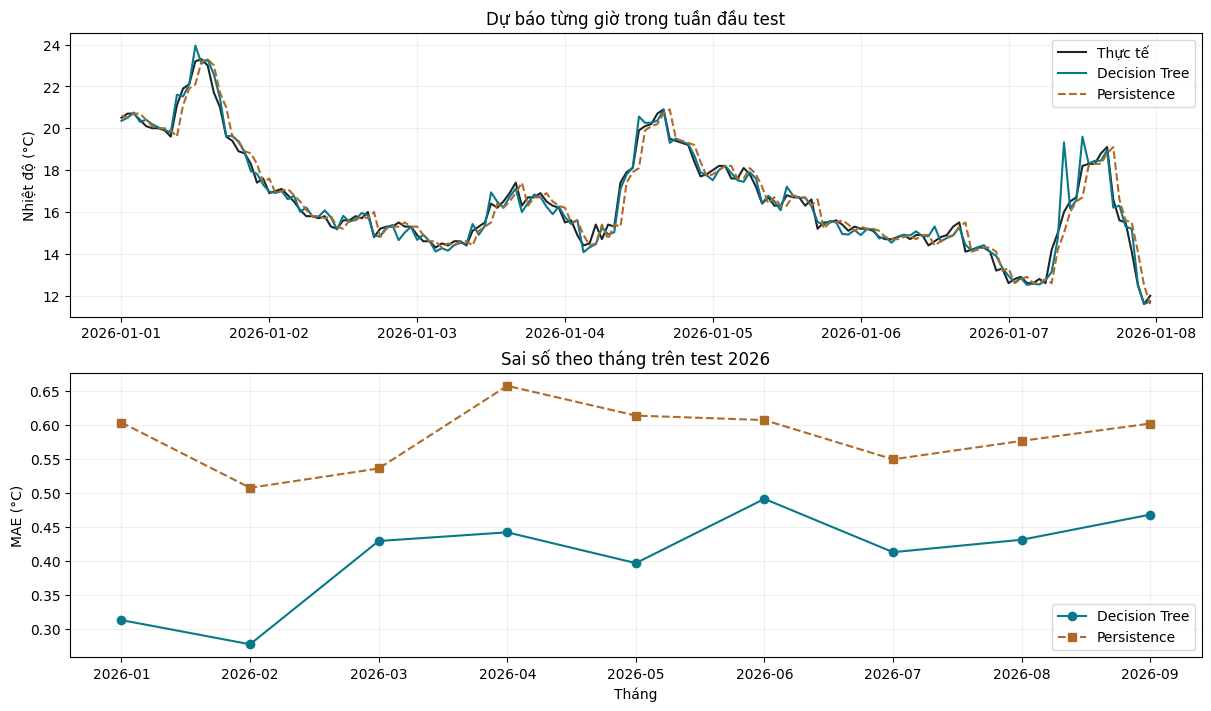

In [6]:
monthly = predictions.assign(
    month=predictions["label_time"].dt.to_period("M").astype(str),
    tree_error=(predictions["Thực tế"] - predictions["Decision Tree"]).abs(),
    baseline_error=(predictions["Thực tế"] - predictions["Persistence"]).abs(),
).groupby("month").agg(
    samples=("Thực tế", "size"),
    decision_tree_mae=("tree_error", "mean"),
    persistence_mae=("baseline_error", "mean"),
)
display(monthly.rename(columns={
    "samples": "Số giờ", "decision_tree_mae": "MAE cây (°C)",
    "persistence_mae": "MAE persistence (°C)",
}).round(4))

week = predictions.head(7 * 24)
fig, axes = plt.subplots(2, 1, figsize=(12, 7), layout="constrained")
for name, color, linestyle in [
    ("Thực tế", "#20252b", "-"),
    ("Decision Tree", "#08788a", "-"),
    ("Persistence", "#b06a27", "--"),
]:
    axes[0].plot(week["label_time"], week[name], label=name, color=color, linestyle=linestyle)
axes[0].set(title="Dự báo từng giờ trong tuần đầu test", ylabel="Nhiệt độ (°C)")
axes[0].legend()
axes[1].plot(monthly.index, monthly["decision_tree_mae"], "o-", color="#08788a", label="Decision Tree")
axes[1].plot(monthly.index, monthly["persistence_mae"], "s--", color="#b06a27", label="Persistence")
axes[1].set(title="Sai số theo tháng trên test 2026", xlabel="Tháng", ylabel="MAE (°C)")
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.2)
plt.show()

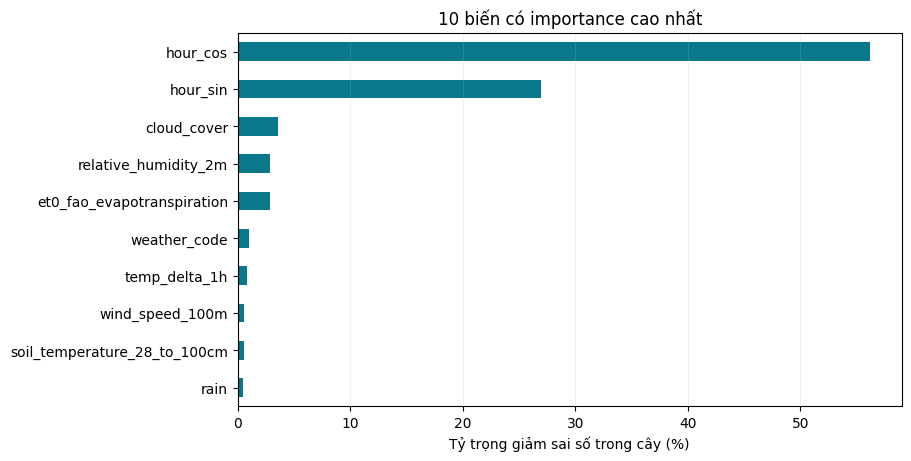

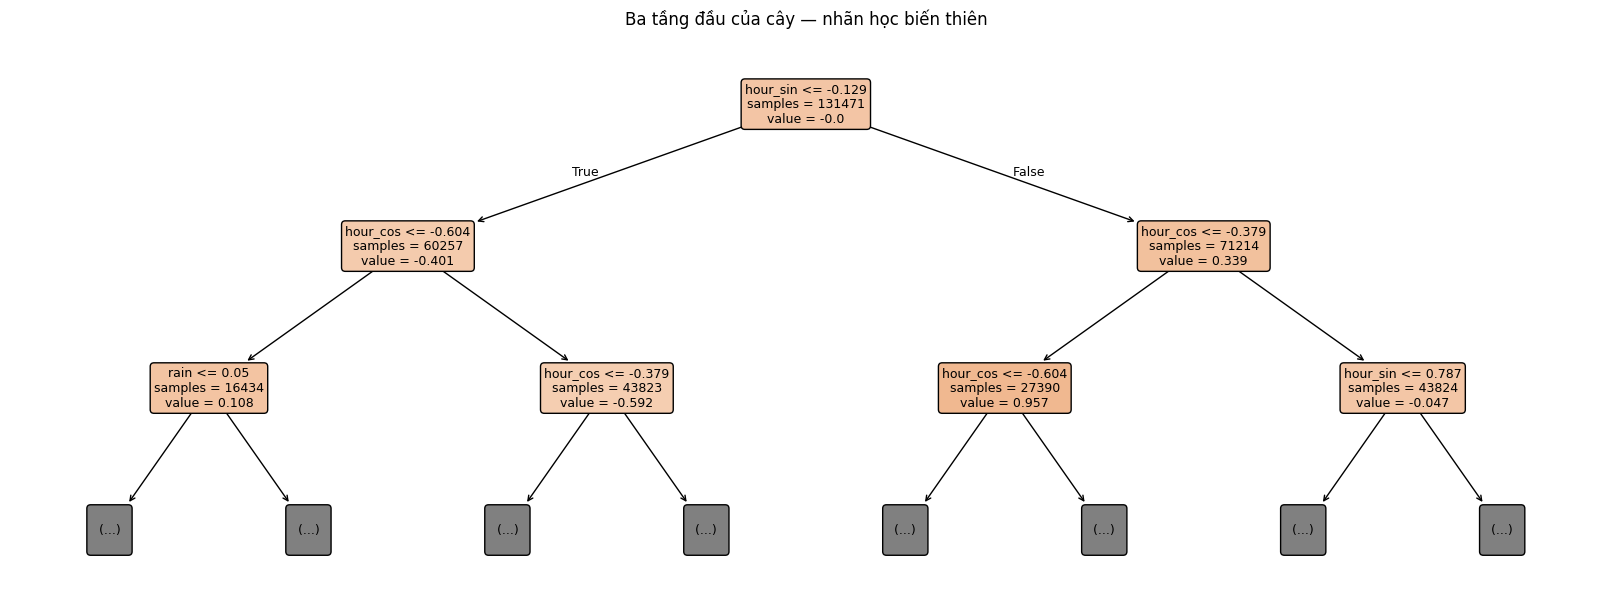

In [7]:
importance = pd.Series(best_model.feature_importances_ * 100, index=features)
top_features = importance.nlargest(10).sort_values()
fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
top_features.plot.barh(ax=ax, color="#08788a")
ax.set(title="10 biến có importance cao nhất", xlabel="Tỷ trọng giảm sai số trong cây (%)")
ax.grid(axis="x", alpha=0.2)
plt.show()

fig, ax = plt.subplots(figsize=(16, 6), layout="constrained")
plot_tree(best_model, max_depth=2, feature_names=features, filled=True, rounded=True,
          impurity=False, fontsize=9, ax=ax)
ax.set_title(f"Ba tầng đầu của cây — nhãn học {best_target_mode.lower()}")
plt.show()

## 6. Tổng kết

In [8]:
tree_mae = test_scores.loc["Decision Tree", "MAE (°C)"]
baseline_mae = test_scores.loc["Persistence", "MAE (°C)"]
difference = baseline_mae - tree_mae
relative_change = abs(difference) / baseline_mae * 100
if difference > 0:
    comparison = f"Cây giảm MAE {relative_change:.1f}% so với persistence."
elif difference < 0:
    comparison = f"MAE của cây cao hơn persistence {relative_change:.1f}%."
else:
    comparison = "Cây và persistence có cùng MAE."

display(Markdown(
    f"Trên **{len(test):,} giờ test**, cây học nhãn **{best_target_mode.lower()}** đạt "
    f"MAE **{tree_mae:.4f} °C** và RMSE **{test_scores.loc['Decision Tree', 'RMSE (°C)']:.4f} °C**. "
    f"Persistence đạt MAE **{baseline_mae:.4f} °C**. {comparison}"
))

Trên **6,528 giờ test**, cây học nhãn **biến thiên** đạt MAE **0.4074 °C** và RMSE **0.6462 °C**. Persistence đạt MAE **0.5841 °C**. Cây giảm MAE 30.3% so với persistence.

Kết quả là backtest một giờ trên dữ liệu tái phân tích ERA5. Tập 2026 từng được dùng trong các thử nghiệm trước của dự án. Bộ biến được kế thừa từ thử nghiệm RF/XGBoost, còn cấu hình cây được chọn trong phạm vi grid và năm validation ở trên.

**Tham khảo**

- [Tài liệu DecisionTreeRegressor của scikit-learn](https://scikit-learn.org/1.7/modules/generated/sklearn.tree.DecisionTreeRegressor.html)
- [Ví dụ dự báo chuỗi thời gian với biến trễ của scikit-learn](https://scikit-learn.org/1.7/auto_examples/applications/plot_time_series_lagged_features.html)